# Information Retrieval: From Keywords to Transformers

Compare BM25 keyword search, corpus-trained Word2Vec static embeddings, and pretrained sentence-transformer semantic search. We measure retrieval quality, setup cost and query latency on the same held-out queries, visualize embeddings, and connect retrieval to a RAG application.

In [1]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / 'src' / 'transformer_retriever.py').is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
sys.path.insert(0, str(PROJECT_ROOT / 'streamlit'))

from bm25_retriever import BM25Retriever
from word2vec_retriever import Word2VecRetriever
from transformer_retriever import TransformerRetriever
from evaluator import IRMetrics
from utils import create_comparison_visualization, print_comparison_table

timings = {}
print('Retrieval modules loaded. Model weights are downloaded on first use.')

/Users/hsin-wenchang/Documents/GitHub/Deep-Learning-Nanodegree-Program-Projects/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1104 14:15:24.763000 2042 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Retrieval modules loaded. Model weights are downloaded on first use.


## Load a reproducible dataset

`DATASET='demo'` runs quickly on the bundled fictional TechFlow AI corpus, also used by Streamlit. Set `DATASET='nq'` to download BEIR Natural Questions (a large download) and evaluate a 200-query sample. The NQ loader restricts the corpus to documents judged for sampled queries: results describe this reduced candidate pool, not full-corpus NQ retrieval.

Word2Vec is trained on document text only. We partition queries into tuning and held-out evaluation sets before any parameter search. All final retrievers use exactly the same held-out queries, corpus, qrels and cutoff. The demo split is query-disjoint but related paraphrases can cross the split, so it is only a smoke test, not evidence of generalization to new topics.

In [2]:
DATASET = 'demo'  # Change to 'nq' for the larger BEIR experiment.
if DATASET == 'demo':
    from demo_data import CORPUS_TEXTS, GROUND_TRUTH
    corpus_texts = list(CORPUS_TEXTS)
    all_queries = list(GROUND_TRUTH)
    all_qrels = {i: {doc: 1 for doc in GROUND_TRUTH[text]}
                 for i, text in enumerate(all_queries)}
elif DATASET == 'nq':
    from data_loader import DataLoader
    loader = DataLoader('BeIR/nq')
    loader.load_dataset(split='test', query_sample_size=200, random_seed=42)
    corpus_texts, all_queries, all_qrels = loader.prepare_retrieval_data()
else:
    raise ValueError("DATASET must be 'demo' or 'nq'.")

if len(all_queries) < 2:
    raise ValueError('Need at least two queries for separate tuning and evaluation.')
query_order = np.random.default_rng(42).permutation(len(all_queries))
n_tuning = max(1, len(all_queries) // 3)
tuning_ids, evaluation_ids = query_order[:n_tuning], query_order[n_tuning:]
tuning_queries = [all_queries[i] for i in tuning_ids]
tuning_qrels = {j: all_qrels.get(int(i), {}) for j, i in enumerate(tuning_ids)}
query_texts = [all_queries[i] for i in evaluation_ids]
qrels_dict = {j: all_qrels.get(int(i), {}) for j, i in enumerate(evaluation_ids)}
print(f'{DATASET}: {len(corpus_texts)} documents; '
      f'{len(tuning_queries)} tuning and {len(query_texts)} held-out queries.')
print('Example held-out query:', query_texts[0])

demo: 5 documents; 7 tuning and 16 held-out queries.
Example held-out query: Where is TechFlow AI located?


## Evaluation metrics and conventions

- **Recall@k:** distinct relevant documents in the first k ranks divided by all relevant documents for the query.
- **Precision@k:** distinct relevant documents in the first k ranks divided by k, even when fewer than k documents are available.
- **MRR:** mean reciprocal rank of the first relevant result. Each retriever returns at most 20 documents here, so reported MRR is truncated to that returned ranking (MRR@20).

A relevance score greater than zero is relevant. We macro-average over every query in qrels, including missing rankings as zero; queries with no positive judgments also contribute zero. Unjudged query IDs in results are ignored. Duplicate results cannot inflate recall or precision. All methods use the same conventions. With only five demo documents, Recall@5 and Recall@10 saturate; Recall@1 and MRR are more informative.

## 1. BM25: keyword baseline

Lowercase and split documents and queries into whitespace-delimited tokens. BM25 scores exact terms using term frequency saturation, inverse document frequency and document-length normalization. It is fast and interpretable, but cannot directly connect synonyms with different spellings. This intentionally simple tokenizer preserves punctuation attached to terms.

In [3]:
bm25_retriever = BM25Retriever()
start = time.perf_counter()
bm25_retriever.build_index(corpus_texts)
build_seconds = time.perf_counter() - start
start = time.perf_counter()
bm25_results = bm25_retriever.retrieve(query_texts, k=20)
timings['BM25 (Keywords)'] = {
    'Setup seconds': build_seconds,
    'Query seconds': time.perf_counter() - start,
}
bm25_metrics = IRMetrics.evaluate_retrieval(bm25_results, qrels_dict)
IRMetrics.print_metrics(bm25_metrics, 'BM25: held-out evaluation')

🔧 Building BM25 index...
✅ BM25 index built for 5 documents
🔍 Running BM25 retrieval for 16 queries...


Retrieving:   0%|          | 0/16 [00:00<?, ?it/s]

Retrieving: 100%|██████████| 16/16 [00:00<00:00, 6067.16it/s]

✅ Retrieved top-20 documents for 16 queries

📊 BM25: held-out evaluation
Recall@1    : 0.6875
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2125
MRR         : 0.8021


## 2. Word2Vec: static-embedding baseline

Lowercase text, remove nonalphabetic characters, English stopwords and tokens shorter than three characters, then train Word2Vec on the corpus. Average in-vocabulary word vectors for each document and query and compare them by cosine similarity. A word has the same vector in every context, so averaging loses word order and cannot disambiguate meanings of words such as 'bank'. A tiny corpus limits the quality of learned associations.

Out-of-vocabulary queries have a zero vector: all scores tie and results are returned in ascending document-index order with a warning, not random or purported semantic matches. A fixed seed, stable hash and one training worker make runs reproducible.

In [4]:
baseline_config = dict(vector_size=100, window=5, min_count=1, sg=0, epochs=20)
word2vec_retriever = Word2VecRetriever(**baseline_config)
word2vec_retriever.build_index(corpus_texts)
stats = word2vec_retriever.get_vocabulary_stats()
print(f"Word2Vec vocabulary: {stats['vocabulary_size']}; dimensions: {stats['vector_size']}")
baseline_results = word2vec_retriever.retrieve(tuning_queries, k=20)
baseline_metrics = IRMetrics.evaluate_retrieval(baseline_results, tuning_qrels)
IRMetrics.print_metrics(baseline_metrics, 'Word2Vec baseline: tuning queries only')

Word2Vec vocabulary: 307; dimensions: 100

📊 Word2Vec baseline: tuning queries only
Recall@1    : 0.5714
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2286
MRR         : 0.7143


### Bounded hyperparameter search

Try four configurations including the baseline, changing vector size, context window, CBOW versus skip-gram, and epochs. Select the highest **tuning MRR**, breaking ties with tuning Recall@5. Held-out labels are not passed into the optimizer. Retain the winning trained model rather than retraining it. Increase the search budget or workers for large corpora only if the validation benefit justifies the cost; multiple workers can reduce reproducibility.

In [5]:
param_combinations = [
    baseline_config,
    dict(vector_size=100, window=10, min_count=1, sg=1, epochs=50),
    dict(vector_size=200, window=5, min_count=1, sg=0, epochs=50),
    dict(vector_size=200, window=10, min_count=1, sg=1, epochs=50),
]
start = time.perf_counter()
optimization = Word2VecRetriever.optimize_parameters(
    param_combinations, corpus_texts, tuning_queries, tuning_qrels, IRMetrics,
)
tuning_seconds = time.perf_counter() - start
display(pd.DataFrame(optimization['results_log'])[['config', 'mrr', 'recall_5']])
print('Selected using tuning queries only:', optimization['best_config'])
word2vec_retriever = optimization['best_retriever']
start = time.perf_counter()
word2vec_results = word2vec_retriever.retrieve(query_texts, k=20)
timings['Word2Vec (Static)'] = {
    'Setup seconds': tuning_seconds,
    'Query seconds': time.perf_counter() - start,
}
word2vec_metrics = IRMetrics.evaluate_retrieval(word2vec_results, qrels_dict)
IRMetrics.print_metrics(word2vec_metrics, 'Optimized Word2Vec: held-out evaluation')

{'vector_size': 100, 'window': 5, 'min_count': 1, 'sg': 0, 'epochs': 20}: validation MRR=0.7143, Recall@5=1.0000


{'vector_size': 100, 'window': 10, 'min_count': 1, 'sg': 1, 'epochs': 50}: validation MRR=0.8929, Recall@5=1.0000
{'vector_size': 200, 'window': 5, 'min_count': 1, 'sg': 0, 'epochs': 50}: validation MRR=0.9286, Recall@5=1.0000


{'vector_size': 200, 'window': 10, 'min_count': 1, 'sg': 1, 'epochs': 50}: validation MRR=0.8214, Recall@5=1.0000


,config,mrr,recall_5
0,"{'vector_size': 100, 'window': 5, 'min_count':...",0.714286,1.0
1,"{'vector_size': 100, 'window': 10, 'min_count'...",0.892857,1.0
2,"{'vector_size': 200, 'window': 5, 'min_count':...",0.928571,1.0
3,"{'vector_size': 200, 'window': 10, 'min_count'...",0.821429,1.0


Selected using tuning queries only: {'vector_size': 200, 'window': 5, 'min_count': 1, 'sg': 0, 'epochs': 50}

📊 Optimized Word2Vec: held-out evaluation
Recall@1    : 0.8125
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2125
MRR         : 0.8750


## 3. Transformer: pretrained semantic search

SentenceTransformers loads Hugging Face's `all-MiniLM-L6-v2`. Batch-encode the corpus once into a `(n_documents, 384)` NumPy array; encode incoming queries using the same model. L2-normalized vector dot products are cosine similarity. Exact search uses bounded query/document blocks rather than allocating the full query-by-corpus score matrix, and partial selection avoids sorting every document when k is small.

Contextual embeddings can connect paraphrases and distinguish word meanings better than static averages, but they are not guaranteed to win every task. Long documents are truncated to the model's token limit: production systems should index overlapping text chunks and track their source documents. Corpus embeddings are cached for the index lifetime; no query causes document re-encoding.

In [6]:
start = time.perf_counter()
transformer_retriever = TransformerRetriever('all-MiniLM-L6-v2', batch_size=64)
transformer_retriever.build_index(corpus_texts)
build_seconds = time.perf_counter() - start
start = time.perf_counter()
transformer_results = transformer_retriever.retrieve(query_texts, k=20)
timings['Transformer (Contextual)'] = {
    'Setup seconds': build_seconds,
    'Query seconds': time.perf_counter() - start,
}
transformer_metrics = IRMetrics.evaluate_retrieval(transformer_results, qrels_dict)
IRMetrics.print_metrics(transformer_metrics, 'MiniLM transformer: held-out evaluation')
print('Corpus embedding shape:', transformer_retriever.corpus_embeddings.shape)

🤖 Loading transformer model: all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 22528.85it/s]

✅ Model loaded: all-MiniLM-L6-v2
🧠 Building semantic index...


✅ Semantic index built for 5 documents
   Embedding dimension: 384
🔍 Running semantic retrieval for 16 queries...
✅ Retrieved top-20 documents using semantic similarity

📊 MiniLM transformer: held-out evaluation
Recall@1    : 0.5938
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2125
MRR         : 0.7646
Corpus embedding shape: (5, 384)


## Compare quality and runtime

Higher retrieval metrics are better; lower setup/query times are better. The table and observations below use actual results, not assumed rankings. Setup includes transformer loading/download and all Word2Vec tuning trials (excluding the exploratory baseline cell), so these are application setup costs rather than comparable pure index-building benchmarks. Query times include encoding/scoring. Hardware, cache warmth and small samples affect timing. Do not select more hyperparameters using this held-out table.

,Recall@1,Recall@5,Recall@10,Precision@5,MRR,Setup seconds,Query seconds,Query ms/query
BM25 (Keywords),0.6875,1.0,1.0,0.2125,0.8021,0.0004,0.0238,1.4894
Word2Vec (Static),0.8125,1.0,1.0,0.2125,0.8750,0.4946,0.0011,0.0677
Transformer (Contextual),0.5938,1.0,1.0,0.2125,0.7646,3.5560,0.1273,7.9557


📊 demo: identical held-out queries
Recall@1    : BM25 (Keywords)=0.6875 | Word2Vec (Static)=0.8125 | Transformer (Contextual)=0.5938
Recall@5    : BM25 (Keywords)=1.0000 | Word2Vec (Static)=1.0000 | Transformer (Contextual)=1.0000
Recall@10   : BM25 (Keywords)=1.0000 | Word2Vec (Static)=1.0000 | Transformer (Contextual)=1.0000
Precision@5 : BM25 (Keywords)=0.2125 | Word2Vec (Static)=0.2125 | Transformer (Contextual)=0.2125
MRR         : BM25 (Keywords)=0.8021 | Word2Vec (Static)=0.8750 | Transformer (Contextual)=0.7646


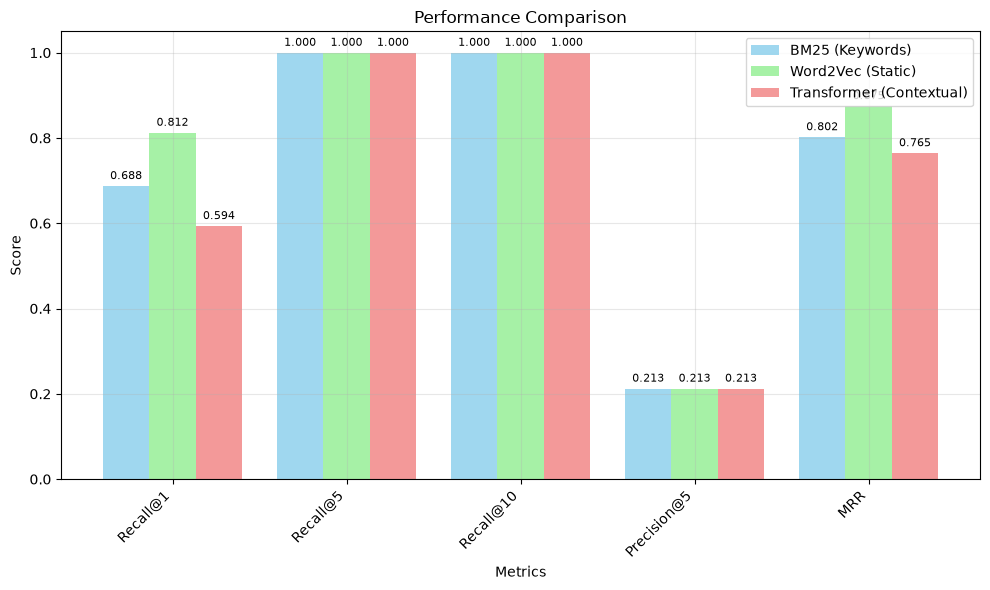

Highest observed held-out MRR: ['Word2Vec (Static)'] (0.8750).
BM25 (Keywords): MRR difference from BM25 = +0.0000
Word2Vec (Static): MRR difference from BM25 = +0.0729
Transformer (Contextual): MRR difference from BM25 = -0.0375
Word2Vec learns only from this corpus; the transformer benefits from external pretraining.
Keyword precision and semantic paraphrase matching are complementary; a hybrid retriever may be useful. This small experiment does not establish a universal winner.


In [7]:
comparison_metrics = {
    'BM25 (Keywords)': bm25_metrics,
    'Word2Vec (Static)': word2vec_metrics,
    'Transformer (Contextual)': transformer_metrics,
}
comparison_table = pd.DataFrame(comparison_metrics).T.join(pd.DataFrame(timings).T)
comparison_table['Query ms/query'] = comparison_table['Query seconds'] * 1000 / len(query_texts)
display(comparison_table.round(4))
print_comparison_table(comparison_metrics, title=f'{DATASET}: identical held-out queries')
create_comparison_visualization(comparison_metrics, show_radar=False)
best_mrr = comparison_table['MRR'].max()
winners = comparison_table.index[comparison_table['MRR'] == best_mrr].tolist()
print(f'Highest observed held-out MRR: {winners} ({best_mrr:.4f}).')
for method in comparison_table.index:
    delta = comparison_table.loc[method, 'MRR'] - bm25_metrics['MRR']
    print(f'{method}: MRR difference from BM25 = {delta:+.4f}')
print('Word2Vec learns only from this corpus; the transformer benefits from external pretraining.')
print('Keyword precision and semantic paraphrase matching are complementary; a hybrid retriever '
      'may be useful. This small experiment does not establish a universal winner.')

### Interpretation of the saved demo run

On the 16 held-out demo queries, Word2Vec achieved MRR **0.8750**, BM25 **0.8021**, and MiniLM **0.7646**. Recall@1 was **0.8125**, **0.6875**, and **0.5938**, respectively. All methods reached Recall@5=1.0 because the candidate pool contains only five documents, so that cutoff cannot distinguish them. Word2Vec's MRR exceeded BM25 by 0.0729, while MiniLM was 0.0375 lower: this is evidence against assuming that a newer representation must always win.

The corpus is tiny, repetitive and domain-specific; Word2Vec was tuned on related questions, while MiniLM was not task-tuned and truncates long documents. These are possible explanations, not isolated causal findings. A query-disjoint split with paraphrases and five candidate documents is too small to establish a general ranking. A larger, topic-separated benchmark and chunking experiment would be needed. Inspect query-level rankings to identify actual failure cases before changing the system.

The saved run measured roughly 1.49 ms/query for BM25, 0.07 ms/query for Word2Vec and 7.96 ms/query for MiniLM, including Python/progress-reporting overhead; these single-run timings are illustrative, not robust microbenchmarks. Results and timings can change with dataset, software, hardware and model versions. Rerun the comparison cells and update this interpretation when changing the configuration.

In [8]:
results_dict = {
    'BM25': bm25_results, 'Word2Vec': word2vec_results, 'Transformer': transformer_results,
}
for query_id, text in enumerate(query_texts[:3]):
    relevant = {doc for doc, score in qrels_dict[query_id].items() if score > 0}
    print(f'\nQuery: {text}\nRelevant document IDs: {sorted(relevant)}')
    for name, results in results_dict.items():
        print(f'  {name}: {results[query_id][:3]}')
    best_doc = transformer_results[query_id][0]
    print('Transformer top document:', corpus_texts[best_doc][:250])


Query: Where is TechFlow AI located?
Relevant document IDs: [0]
  BM25: [0, 4, 1]
  Word2Vec: [3, 2, 0]
  Transformer: [0, 2, 1]
Transformer top document: TechFlow AI is a leading artificial intelligence company founded in January 2020 by five Stanford PhD graduates. Our company specializes in developing cutting-edge machine learning models, deep learning architectures, and AI-powered enterprise automa

Query: What is FlowBot?
Relevant document IDs: [1]
  BM25: [0, 1, 4]
  Word2Vec: [1, 2, 3]
  Transformer: [1, 2, 0]
Transformer top document: TechFlow AI offers four main AI-powered products for enterprise customers. FlowBot is our flagship intelligent workflow automation platform that uses advanced machine learning to optimize business processes, reduce manual tasks, and increase operatio

Query: How much funding did TechFlow AI raise?
Relevant document IDs: [2]
  BM25: [2, 3, 4]
  Word2Vec: [2, 0, 3]
  Transformer: [2, 0, 4]
Transformer top document: In 2024, TechFlow AI achieved rem

## Visualize the embedding space with PCA

Fit one two-dimensional PCA projection jointly to normalized document and held-out query embeddings. Circles are documents; crosses are queries, colored by their first relevant document ID (demo) or marked together (larger datasets). Nearby points suggest similar representations in this projection; queries about the same subject may cluster near a relevant document. Document labels and query annotations make the small demo interpretable. PCA preserves high-variance directions, not all cosine distances: overlap or separation in 2D is not a retrieval-quality metric. The explained-variance label shows how much information the projection retains.

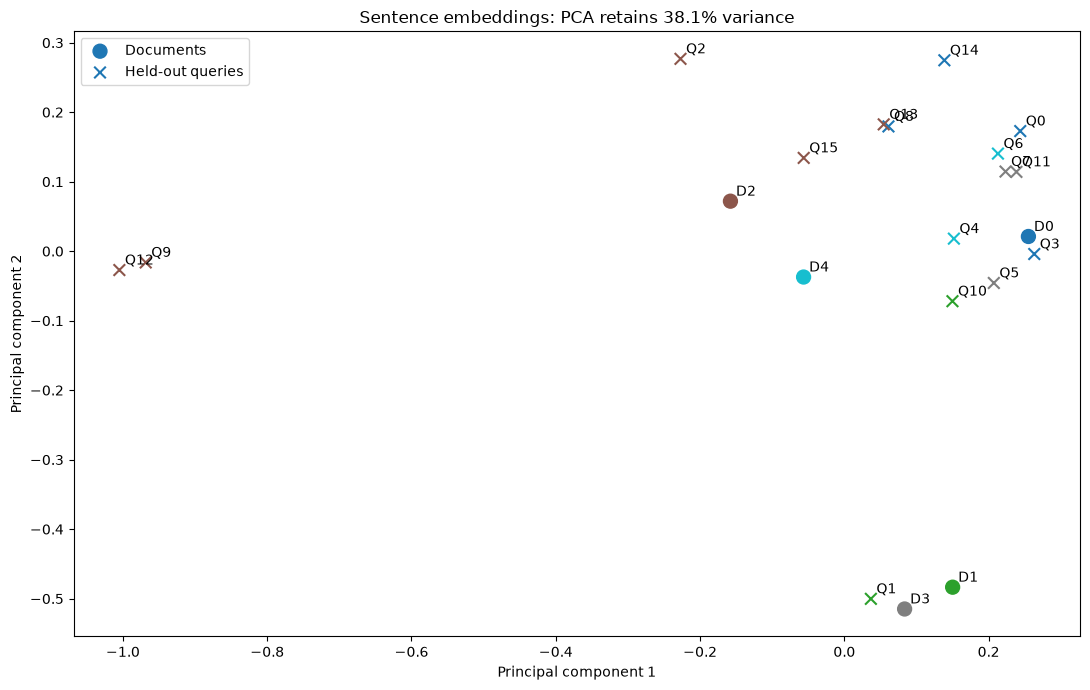

In [9]:
from sklearn.decomposition import PCA

query_embeddings = transformer_retriever.model.encode(
    query_texts, batch_size=64, convert_to_numpy=True,
    normalize_embeddings=True, show_progress_bar=False,
)
plot_doc_count = min(len(corpus_texts), 200)
plot_query_count = min(len(query_texts), 100)
vectors = np.vstack([
    transformer_retriever.corpus_embeddings[:plot_doc_count],
    query_embeddings[:plot_query_count],
])
pca = PCA(n_components=2, svd_solver='full')
points = pca.fit_transform(vectors)
fig, ax = plt.subplots(figsize=(11, 7))
doc_colors = np.arange(plot_doc_count) if DATASET == 'demo' else 'tab:blue'
query_colors = [next((doc for doc, rel in qrels_dict[i].items() if rel > 0), -1)
                for i in range(plot_query_count)] if DATASET == 'demo' else 'tab:orange'
color_options = dict(cmap='tab10', vmin=0, vmax=max(1, plot_doc_count - 1)) if DATASET == 'demo' else {}
ax.scatter(*points[:plot_doc_count].T, c=doc_colors, marker='o', s=100,
           label='Documents', **color_options)
ax.scatter(*points[plot_doc_count:].T, c=query_colors, marker='x', s=70,
           label='Held-out queries', **color_options)
if DATASET == 'demo':
    for i, (x, y) in enumerate(points):
        label = f'D{i}' if i < plot_doc_count else f'Q{i - plot_doc_count}'
        ax.annotate(label, (x, y), xytext=(4, 4), textcoords='offset points')
ax.set(title=f'Sentence embeddings: PCA retains {pca.explained_variance_ratio_.sum():.1%} variance',
       xlabel='Principal component 1', ylabel='Principal component 2')
ax.legend()
plt.tight_layout()
plt.show()

## The retriever's role in Retrieval-Augmented Generation (RAG)

**Retrieval comes first, generation second.** Index a knowledge corpus offline. At question time, the retriever selects the top-k relevant documents or chunks. Put those passages, source IDs and the question into a generator's prompt; a large language model then synthesizes an answer grounded in the retrieved evidence and cites its sources. Retrieval does not itself generate an answer or update the generator's weights. Missing or misleading evidence can cause bad answers even with a strong generator; instructing the model to acknowledge insufficient evidence helps but does not guarantee correctness.

Tools such as **Perplexity**, search-enabled **ChatGPT**, and code-context features in **Copilot** illustrate retrieval followed by generation, although their production implementations are more complex and need not use the models in this exercise. RAG can supply current or private information without retraining the LLM. Access control, source freshness, prompt-injection defenses, reranking and grounded-answer evaluation are important in production.

Our measured comparison illustrates the progression: **BM25** rewards exact words, **Word2Vec** adds corpus-learned word associations but averages static vectors, and **transformers** use contextual sentence representations learned from large external datasets. Inspect the held-out table and example rankings to see which approach works on this dataset; semantic search is not automatically more accurate than keywords. Hybrid search can combine their strengths. Retrieval Recall/Precision/MRR measure evidence selection, not the factuality of the generated answer.

### Streamlit demo

From the project directory run `python -m streamlit run streamlit/app.py`. All three indexes are cached across UI reruns and use the same document IDs. The default MiniLM transformer keeps startup lightweight. Try a sample query and compare the documents, Recall@k, Precision@k and reciprocal rank. Retrieval works without an API key. Answer generation is optional and calls an external provider: enable it only for non-sensitive data you are authorized to send; do not submit private code, personal data or credentials. The bundled documents describe a fictional company. No external generation call is needed to evaluate retrieval.

In [10]:
from demo_data import CORPUS_TEXTS, GROUND_TRUTH

# Reuse existing indexes in demo mode; NQ indexes have different document IDs.
if DATASET == 'demo':
    demo_retrievers = {
        'BM25': bm25_retriever, 'Word2Vec': word2vec_retriever,
        'Transformer': transformer_retriever,
    }
else:
    demo_retrievers = {
        'BM25': BM25Retriever(), 'Word2Vec': Word2VecRetriever(epochs=50, sg=1),
        'Transformer': TransformerRetriever(),
    }
    for retriever in demo_retrievers.values():
        retriever.build_index(CORPUS_TEXTS)

demo_query = 'What products does TechFlow AI offer?'
demo_qrels = {0: {doc: 1 for doc in GROUND_TRUTH[demo_query]}}
for name, retriever in demo_retrievers.items():
    ranking = retriever.retrieve([demo_query], k=3)
    assert set(ranking) == {0}
    assert len(ranking[0]) == 3 and len(set(ranking[0])) == 3
    assert all(isinstance(doc, int) and 0 <= doc < len(CORPUS_TEXTS) for doc in ranking[0])
    print(name, ranking)
    IRMetrics.print_metrics(IRMetrics.evaluate_retrieval(ranking, demo_qrels), name)
print('All three retrievers satisfy the shared demo interface; no generator API call was made.')

🔍 Running BM25 retrieval for 1 queries...


Retrieving:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving: 100%|██████████| 1/1 [00:00<00:00, 5084.00it/s]

✅ Retrieved top-3 documents for 1 queries
BM25 {0: [1, 3, 4]}

📊 BM25
Recall@1    : 1.0000
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2000
MRR         : 1.0000
Word2Vec {0: [4, 0, 1]}

📊 Word2Vec
Recall@1    : 0.0000
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2000
MRR         : 0.3333
🔍 Running semantic retrieval for 1 queries...


✅ Retrieved top-3 documents using semantic similarity
Transformer {0: [0, 1, 2]}

📊 Transformer
Recall@1    : 0.0000
Recall@5    : 1.0000
Recall@10   : 1.0000
Precision@5 : 0.2000
MRR         : 0.5000
All three retrievers satisfy the shared demo interface; no generator API call was made.


## Optional: compare larger sentence transformers

The main comparison uses MiniLM for speed. Set `RUN_EXTRA_MODELS=True` to compare MPNet and BGE-small, with additional model downloads and setup cost. These are exploratory held-out results, not permission to tune on the test labels. MPNet uses a larger pretrained sentence encoder; BGE-small is optimized for retrieval. Failures are reported as errors rather than replaced with invented scores. BGE's query instruction is applied only to queries. No model is assumed to win.

In [11]:
RUN_EXTRA_MODELS = False
extra_metrics = {'MiniLM-L6-v2': transformer_metrics}
if RUN_EXTRA_MODELS:
    configurations = [
        ('MPNet-base', 'sentence-transformers/all-mpnet-base-v2', ''),
        ('BGE-small', 'BAAI/bge-small-en-v1.5',
         'Represent this sentence for searching relevant passages: '),
    ]
    for name, model_id, prefix in configurations:
        extra = TransformerRetriever(model_id)
        extra.build_index(corpus_texts)
        ranking = extra.retrieve([prefix + query for query in query_texts], k=20)
        extra_metrics[name] = IRMetrics.evaluate_retrieval(ranking, qrels_dict)
        IRMetrics.print_metrics(extra_metrics[name], name)
        del extra
    display(pd.DataFrame(extra_metrics).T)
else:
    print('Optional model downloads skipped. Main three-retriever comparison is complete.')

Optional model downloads skipped. Main three-retriever comparison is complete.
